<a href="https://colab.research.google.com/github/franciscoweitzman-cyber/aps_francisco_weitzman/blob/main/TS8_GRUPO1/TS8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Análisis y Procesamiento de Señales

# Tarea Semanal 8 — Filtrado No Lineal
 **GRUPO 1:** *Del Monaco, García Corona, Miranda, Weitzman.*

## Introducción

En la tarea semanal anterior se trabajó con filtros digitales lineales, tanto IIR como FIR. Para que un sistema sea lineal, este debe cumplir con el principio de superposición, es decir, la respuesta total del sistema debe coincidir si se calcula la suma del aporte que genera cada impulso o la suma de los impulsos. Si además es invariante en el tiempo, la respuesta al impulso contiene toda la información necesaria sobre el sistema, así como también lo hace su respuesta en frecuencia.

El ECG captura la actividad eléctrica del corazón y en cada latido presenta una onda P, el complejo QRS y la onda T. En este proyecto se optó por estimar las interferencias $\left(b[n]\right)$ en el dominio del tiempo y se le resta a la señal regitrada $\left(s[n]\right)$

$$\hat{x}[n]=s[n]-\hat{b}[n]$$

Los estimadores aplicados son no lineales o dependientes de la señal, esto implica que no cumple con el principio de superposición y por lo tanto no cuentan con una respuesta en frecuencia que los describa.

**Filtro de mediana**

Reemplaza cada muestra por la mediana de una ventana de $L$ muestras:

$$m[n]=med \left( s[n],s[n-1],...,s[n-L+1] \right)$$

La mediana se obtiene ordenando los valores y tomando el central, no es una combinación lineal. Es por esto que la mediana de una suma de señales no es siempre la suma de las medianas.

**Interpolación por splines cúbicos**

Entre la onda P y el complejo QRS, el impulso cardíaco se demora al atravesar el nódulo aurículo-ventricular y la actividad eléctrica es aproximadamente nula. Ese segmento PQ define el nivel isoeléctrico. Lo que se mide en ese tramo es interferencia. Si se toma un punto por latido en ese segmento se obtiene un muestreo no uniforme de la línea de base, a una muestra por latido. Para llevarla a una frecuencia de muestreo del ECG se interpola con un spline cúbico. Con esta herramienta se genera una curva formada por polinómios de tercer grado entre puntos consecutivos, con primera y segunda derivada continuas en las uniones. Como resultado se obtiene una estimación suave que pasa exactamente por los puntos medidos. Como esos puntos se ubican a partir de los latidos detectados en la propia señal, el procedimiento tampoco es un sistema LTI.

## Desarrollo
Arrancamos por iniciar el código, cargar el archivo y a trabajar sobre el filtro de mediana.

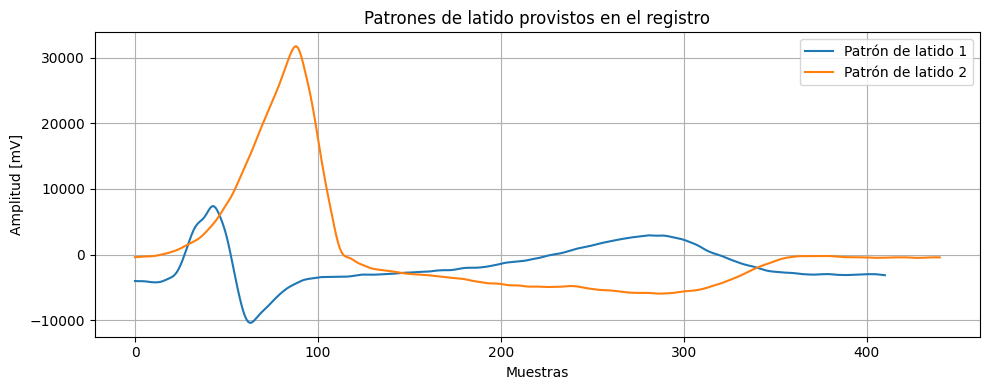

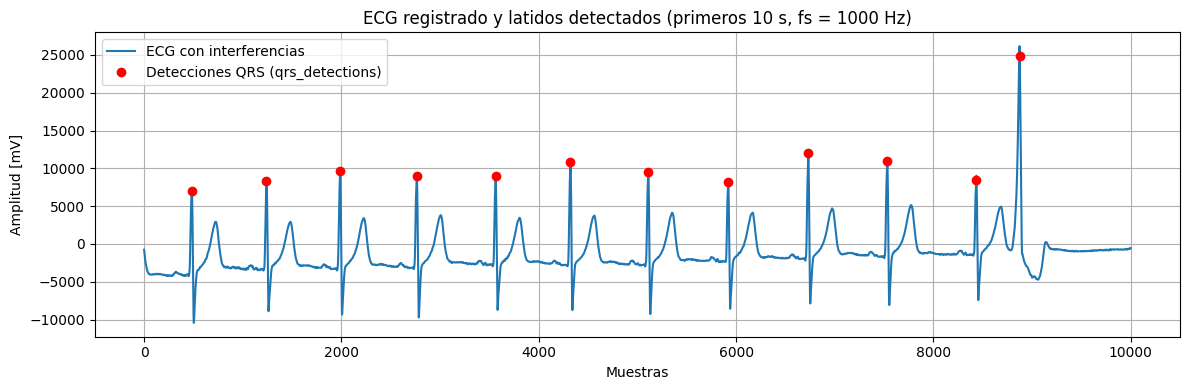

In [ ]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
import scipy.io as sio
import os
from scipy.interpolate import CubicSpline

url_mat = 'https://github.com/franciscoweitzman-cyber/aps_francisco_weitzman/raw/refs/heads/main/TS7/ECG_TP4.mat'
nombre_archivo = 'ECG_TP4.mat'
os.system(f'wget "{url_mat}" -O {nombre_archivo}')
# =============================================================================
#  Importo de ECG con ruido #
# =============================================================================
fs_ecg = 1000 # Hz
sio.whosmat('ECG_TP4.mat')
mat_struct = sio.loadmat('./ECG_TP4.mat')



##################
# Lectura de ECG #
##################

fs_ecg = 1000 # Hz

##################
## ECG con ruido
##################

ecg_one_lead_rs = (mat_struct['ecg_lead']*1.0).flatten()
N = len(ecg_one_lead_rs)

nn = np.arange(0,N)
############
# Patrones Cardíacos
############
hb_1 = mat_struct['heartbeat_pattern1'].flatten()
hb_2 = mat_struct['heartbeat_pattern2'].flatten()
plt.figure(figsize=(10, 4))
plt.plot(hb_1, label='Patrón de latido 1')
plt.plot(hb_2, label='Patrón de latido 2')
plt.title('Patrones de latido provistos en el registro')
plt.xlabel('Muestras')
plt.ylabel('Amplitud [mV]')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


qrs_detections = mat_struct['qrs_detections'].flatten()

############
## Gráfico Inicial
############

N_plot = 10000                                        # muestras a visualizar
qrs_plot = qrs_detections[qrs_detections < N_plot]    # detecciones dentro de ese tramo

plt.figure(figsize=(12, 4))
plt.plot(nn[:N_plot], ecg_one_lead_rs[:N_plot], label='ECG con interferencias')
plt.plot(qrs_plot, ecg_one_lead_rs[qrs_plot], 'o', color='red', label='Detecciones QRS (qrs_detections)')
plt.title(f'ECG registrado y latidos detectados (primeros {N_plot / fs_ecg:.0f} s, fs = {fs_ecg} Hz)')
plt.xlabel('Muestras')
plt.ylabel('Amplitud [mV]')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

###Mediana
Este filtro consiste en tomar el percentil 50 de nuestras amplitudes ordenadas, es decir, elige la muestra más probable o popular de una cantidad N de muestras. Por este motivo, si la cantidad de muestras es más que el doble de lo que queremos que pase, la mediana lo va a filtrar. Un ejemplo:


....|||...


esa señal tiene 3 valores de interés, si elegimos una mediana de 7 valores, nunca va a llegar a la mitad de tabla, entonces la va a filtrar. Si la muestra 8 fuera mayor a las 3 de interés, también entraría el valor de interés. Es una consecuencia de la alinealidad de este filtro.

En este caso elegimos 201 para que tenga la misma cantidad de lecturas antes y después de la muestra central, y porque es un tamaño comparable con el orden del doble del tamaño de nuestras ondas Q, R y S, por lo que si sustraemos esto a nuestra señal, las ondas Q, R y S no se van a ver afectadas. En este caso, funciona como un filtro pasa bajos.

La mediana de 601 valores va a filtrar todo lo que sea menor a 300ms que son del orden de las ondas P y T. Este también actúa como un pasa bajos, pero no lo usamos directamente por lo antes mencionado: los picos de QRS añadirían amplitudes en las frecuencias más altas que levanta la vara en el percentil 50, así que resulta conveniente primero eliminar esos picos.

In [ ]:
#%% Filtros no lineales
# Mediana
b_200 = sig.medfilt(ecg_one_lead_rs, 201)
b_hat = sig.medfilt(b_200, 601)
ecg_medfilt2 = ecg_one_lead_rs - b_hat
ecg_medfilt = ecg_one_lead_rs - b_200

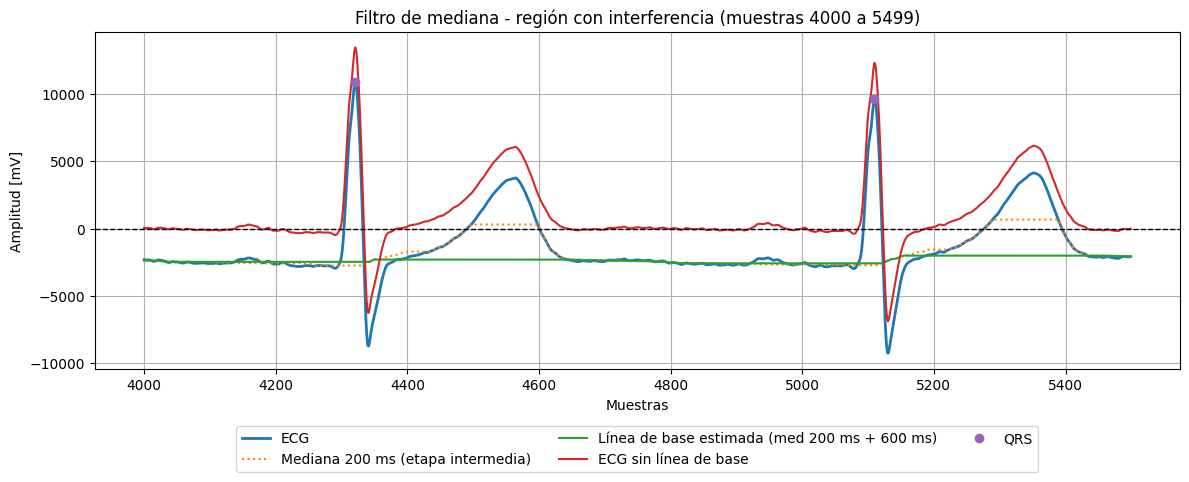

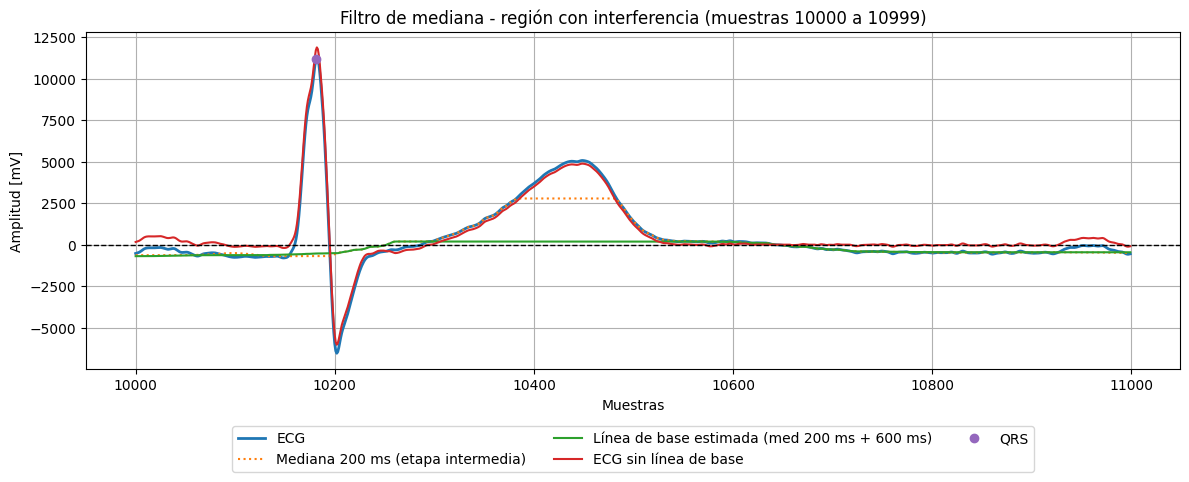

In [ ]:
# =============================================================================
#  Gráficos por regiones de interés - Filtro de mediana
# =============================================================================
cant_muestras = N

regs_interes = (
        [4000, 5500],   # muestras
        [10e3, 11e3],   # muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    # Máscara para quedarse solo con los latidos que caen dentro de zoom_region
    mask_qrs = (qrs_detections >= zoom_region[0]) & (qrs_detections <= zoom_region[-1])

    plt.figure(figsize=(12, 5))
    plt.plot(zoom_region, ecg_one_lead_rs[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, b_200[zoom_region], ':', label='Mediana 200 ms (etapa intermedia)')
    plt.plot(zoom_region, b_hat[zoom_region], label='Línea de base estimada (med 200 ms + 600 ms)')
    plt.plot(zoom_region, ecg_medfilt2[zoom_region], label='ECG sin línea de base')

    plt.plot(qrs_detections[mask_qrs], ecg_one_lead_rs[qrs_detections[mask_qrs]], 'o', label='QRS')

    plt.axhline(0, color='k', linestyle='--', linewidth=1)
    plt.title(f'Filtro de mediana - región con interferencia (muestras {int(zoom_region[0])} a {int(zoom_region[-1])})')
    plt.xlabel('Muestras')
    plt.ylabel('Amplitud [mV]')
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

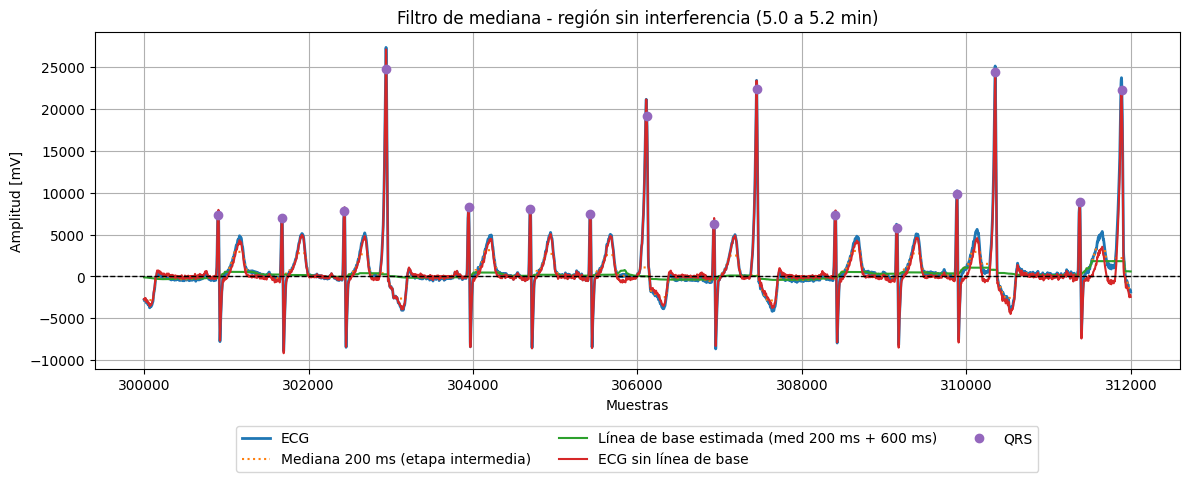

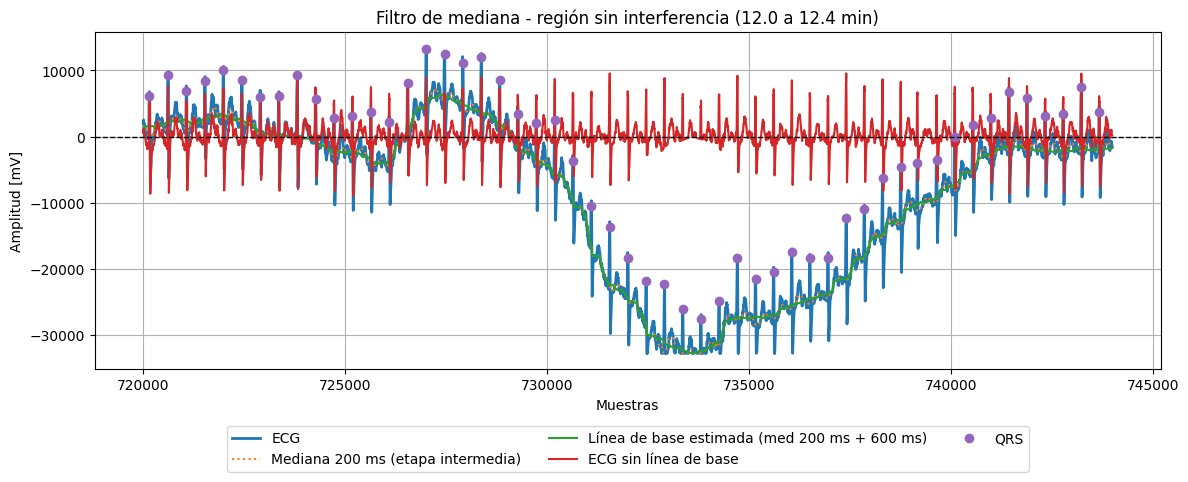

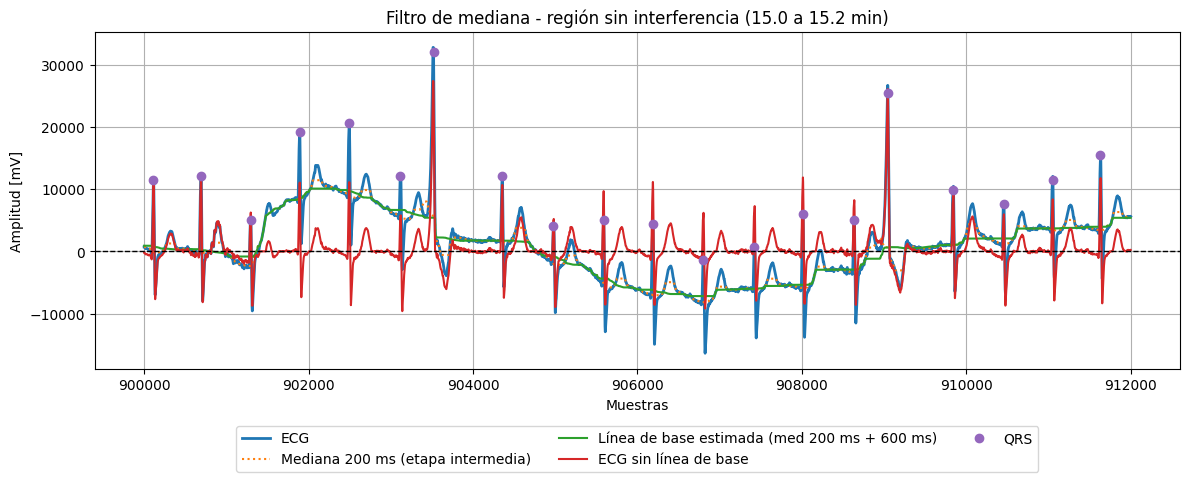

In [ ]:
#################################
# Regiones de interés sin ruido #
#################################

regs_interes = (
        np.array([5, 5.2]) *60*fs_ecg, # minutos a muestras
        np.array([12, 12.4]) *60*fs_ecg, # minutos a muestras
        np.array([15, 15.2]) *60*fs_ecg, # minutos a muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    # Máscara para quedarse solo con los latidos que caen dentro de zoom_region
    mask_qrs = (qrs_detections >= zoom_region[0]) & (qrs_detections <= zoom_region[-1])

    plt.figure(figsize=(12, 5))
    plt.plot(zoom_region, ecg_one_lead_rs[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, b_200[zoom_region], ':', label='Mediana 200 ms (etapa intermedia)')
    plt.plot(zoom_region, b_hat[zoom_region], label='Línea de base estimada (med 200 ms + 600 ms)')
    plt.plot(zoom_region, ecg_medfilt2[zoom_region], label='ECG sin línea de base')

    plt.plot(qrs_detections[mask_qrs], ecg_one_lead_rs[qrs_detections[mask_qrs]], 'o', label='QRS')

    plt.axhline(0, color='k', linestyle='--', linewidth=1)
    plt.title(f'Filtro de mediana - región sin interferencia ({zoom_region[0]/60/fs_ecg:.1f} a {zoom_region[-1]/60/fs_ecg:.1f} min)')
    plt.xlabel('Muestras')
    plt.ylabel('Amplitud [mV]')
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
#%%Splines cúbicos
start_win = qrs_detections-60
end_win = qrs_detections-40
pq_hat = np.array([ np.mean(ecg_one_lead_rs[a:b]) for a,b in zip(start_win, end_win) ])
pq_t_hat = np.array([ np.mean([a,b]) for a,b in zip(start_win, end_win) ])


b_spline = CubicSpline(pq_t_hat,pq_hat)
ecg_spline = ecg_one_lead_rs - b_spline(nn)

-3016.3


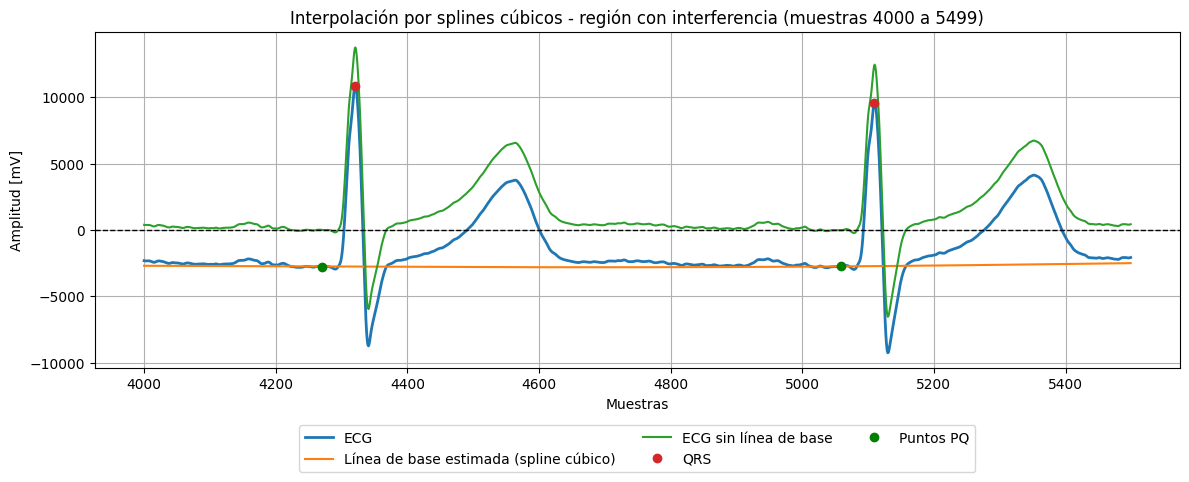

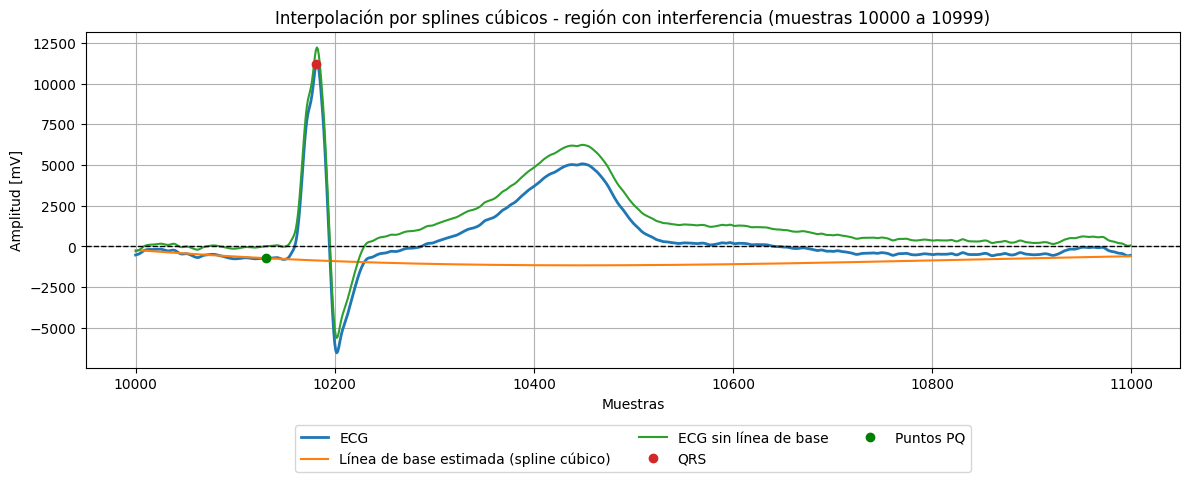

In [ ]:
##########################################
# Gráficos Regiones de interés con ruido #
##########################################

cant_muestras = N

regs_interes = (
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    # Máscaras para filtrar solo los puntos que caen dentro de zoom_region
    mask_qrs = (qrs_detections >= zoom_region[0]) & (qrs_detections <= zoom_region[-1])
    mask_pq  = (pq_t_hat >= zoom_region[0]) & (pq_t_hat <= zoom_region[-1])

    plt.figure(figsize=(12, 5))
    plt.plot(zoom_region, ecg_one_lead_rs[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, b_spline(zoom_region), label='Línea de base estimada (spline cúbico)')
    plt.plot(zoom_region, ecg_spline[zoom_region], label='ECG sin línea de base')

    plt.plot(qrs_detections[mask_qrs], ecg_one_lead_rs[qrs_detections[mask_qrs]], 'o', label='QRS')
    plt.plot(pq_t_hat[mask_pq], pq_hat[mask_pq], 'og', label='Puntos PQ')

    plt.axhline(0, color='k', linestyle='--', linewidth=1)
    plt.title(f'Interpolación por splines cúbicos - región con interferencia (muestras {int(zoom_region[0])} a {int(zoom_region[-1])})')
    plt.xlabel('Muestras')
    plt.ylabel('Amplitud [mV]')
    plt.grid(True)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
    plt.tight_layout()
    plt.show()

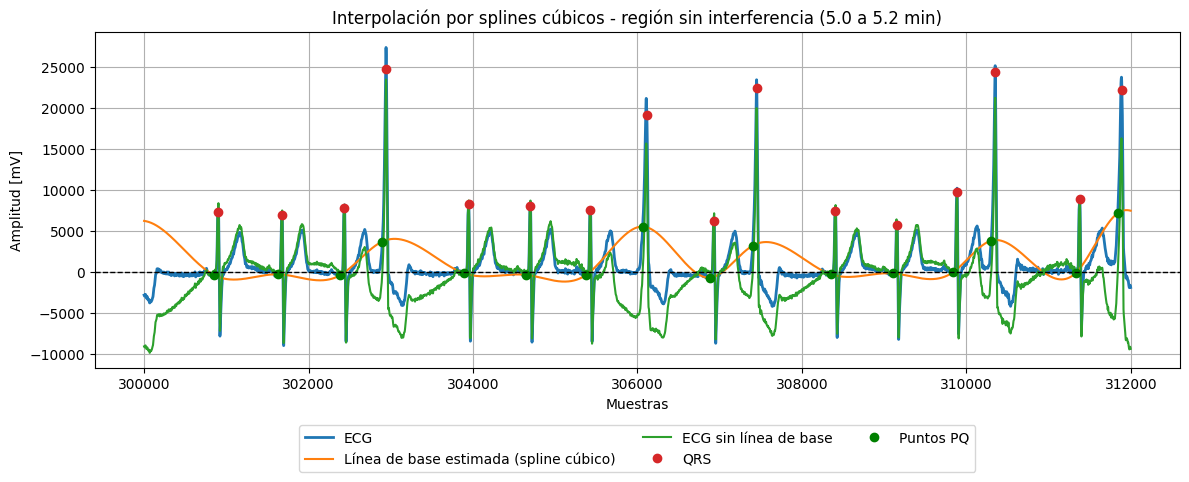

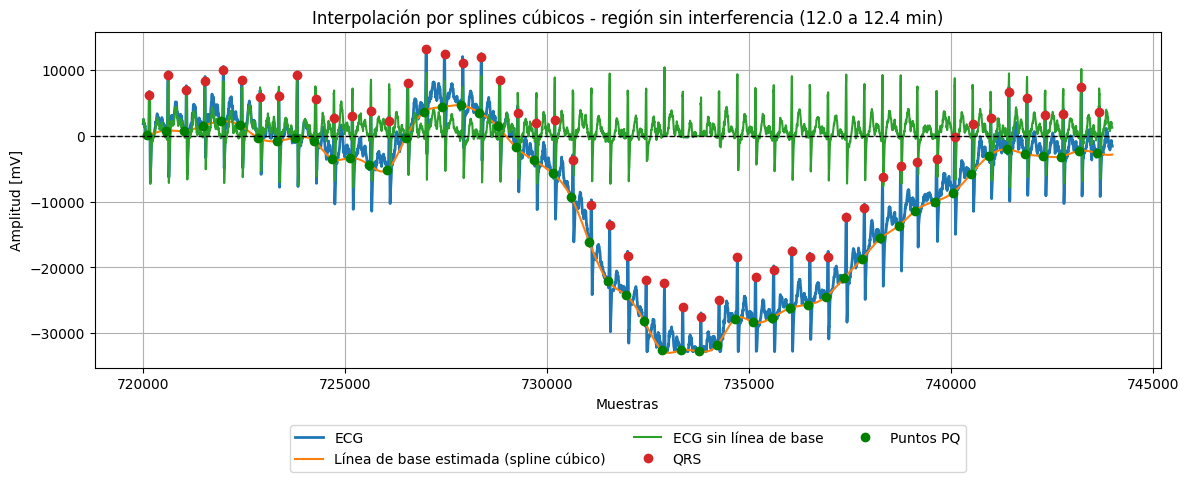

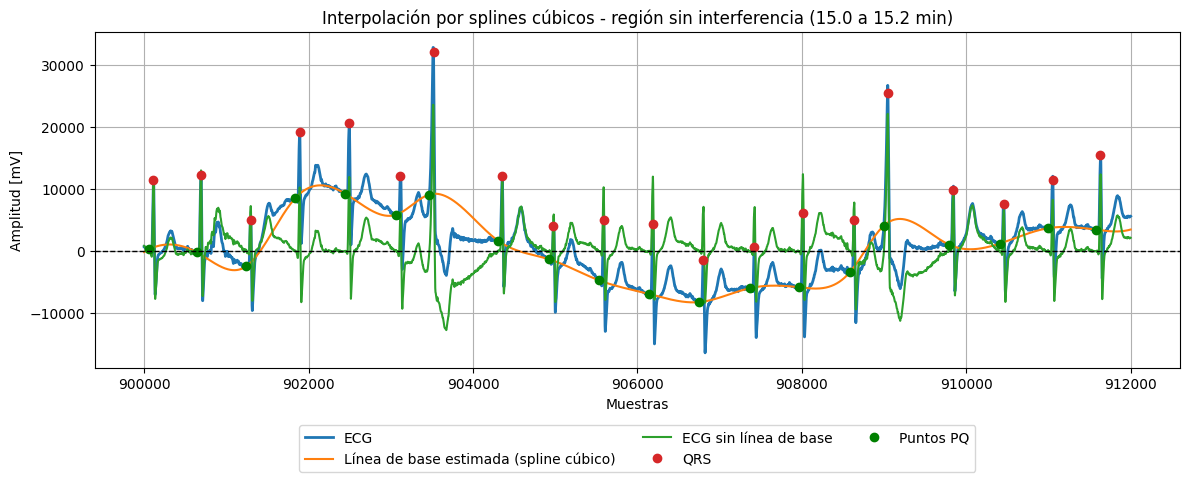

In [ ]:
##########################################
# Gráficos Regiones de interés sin ruido #
##########################################

regs_interes = (
        np.array([5, 5.2]) *60*fs_ecg, # minutos a muestras
        np.array([12, 12.4]) *60*fs_ecg, # minutos a muestras
        np.array([15, 15.2]) *60*fs_ecg, # minutos a muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    # Máscaras para filtrar solo los puntos que caen dentro de zoom_region
    mask_qrs = (qrs_detections >= zoom_region[0]) & (qrs_detections <= zoom_region[-1])
    mask_pq  = (pq_t_hat >= zoom_region[0]) & (pq_t_hat <= zoom_region[-1])

    plt.figure(figsize=(12, 5))
    plt.plot(zoom_region, ecg_one_lead_rs[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, b_spline(zoom_region), label='Línea de base estimada (spline cúbico)')
    plt.plot(zoom_region, ecg_spline[zoom_region], label='ECG sin línea de base')

    plt.plot(qrs_detections[mask_qrs], ecg_one_lead_rs[qrs_detections[mask_qrs]], 'o', label='QRS')
    plt.plot(pq_t_hat[mask_pq], pq_hat[mask_pq], 'og', label='Puntos PQ')

    plt.axhline(0, color='k', linestyle='--', linewidth=1)
    plt.title(f'Interpolación por splines cúbicos - región sin interferencia ({zoom_region[0]/60/fs_ecg:.1f} a {zoom_region[-1]/60/fs_ecg:.1f} min)')
    plt.xlabel('Muestras')
    plt.ylabel('Amplitud [mV]')
    plt.grid(True)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
    plt.tight_layout()
    plt.show()